In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import (
    RandomForestRegressor, GradientBoostingRegressor,
    HistGradientBoostingRegressor, GradientBoostingClassifier
)
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 42
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.max_columns', 12)
print('Python:', sys.version.split()[0], 'scikit-learn:', sklearn.__version__)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

Python: 3.12.13 scikit-learn: 1.7.2


In [2]:
y, pred = 35., 20.

def half_squared_loss(prediction):
    return 0.5 * (y-prediction)**2

epsilon = 1e-5
numeric = (half_squared_loss(pred + epsilon) - 
           half_squared_loss(pred - epsilon)) / (2*epsilon)

analytic = pred - y

print("Residual: ", y - pred)
print("Numerical dL/dF:", round(numeric, 5))
print("Analytic dL/dF: ", analytic)
assert np.isclose(numeric, analytic, atol = 1e-6)



Residual:  15.0
Numerical dL/dF: -15.0
Analytic dL/dF:  -15.0


In [3]:
x_toy = np.arange(1, 7, dtype = float)
y_toy = np.array([12., 14, 15, 28, 32, 35])
F0 = np.full_like(y_toy, y_toy.mean())

r0 = y_toy - F0

toy_table = pd.DataFrame({
    "distance_km": x_toy, "actual_min": y_toy,
    "first_guess": F0, "residual": r0
})

print(toy_table.round(2).to_string(index = False))
print("Mean target: ", round(y_toy.mean(), 3))
print("First model MSE = ", round(mean_squared_error(y_toy, F0), 3))

 distance_km  actual_min  first_guess  residual
         1.0        12.0        22.67    -10.67
         2.0        14.0        22.67     -8.67
         3.0        15.0        22.67     -7.67
         4.0        28.0        22.67      5.33
         5.0        32.0        22.67      9.33
         6.0        35.0        22.67     12.33
Mean target:  22.667
First model MSE =  85.889


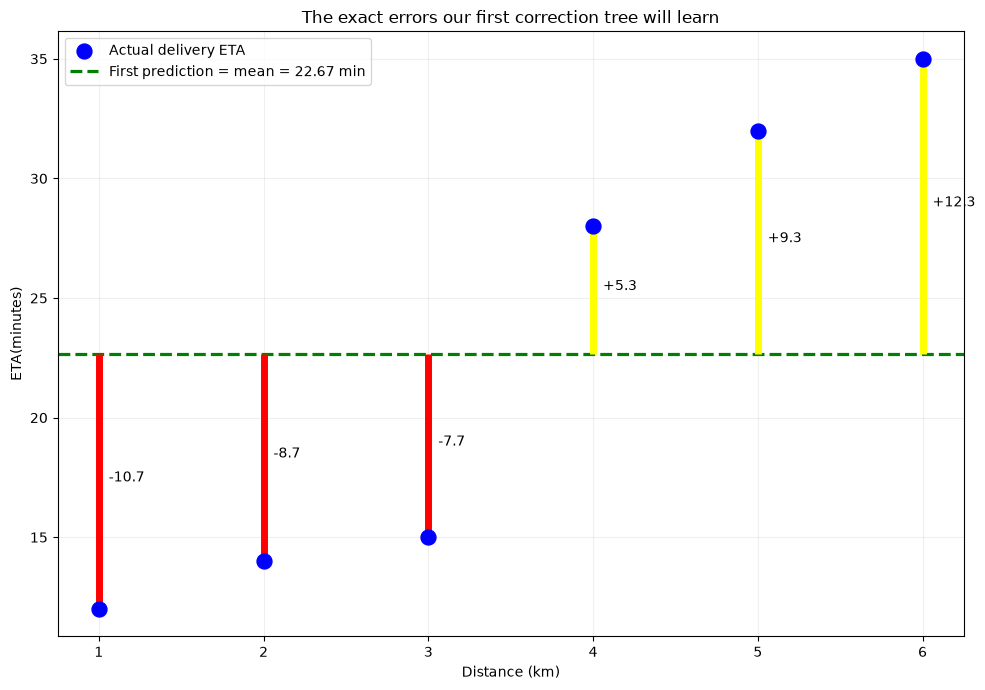

In [5]:
fig, ax = plt.subplots(figsize = (10,7))
ax.scatter(x_toy, y_toy, s = 115, color = 'blue', label = 'Actual delivery ETA', zorder = 5)
ax.axhline(y_toy.mean(), ls = "--", lw = 2.3, color = 'green', 
           label = f"First prediction = mean = {y_toy.mean():.2f} min")
for xx, yy, baseline in zip(x_toy, y_toy, F0):
    color = 'red' if yy < baseline else 'yellow'
    ax.vlines(xx, min(yy, baseline), max(yy, baseline), color = color, lw = 5)
    ax.text(xx+0.06, (yy+baseline)/2, f"{yy-baseline:+.1f}", fontsize=10)
ax.set(xlabel = 'Distance (km)', ylabel = 'ETA(minutes)', 
title = 'The exact errors our first correction tree will learn')
ax.set_xticks(x_toy)
ax.legend()
ax.grid(alpha = 0.2)
plt.tight_layout()
plt.show()

In [6]:
eta = 0.5
stump = DecisionTreeRegressor(max_depth=1, random_state=SEED)
stump.fit(x_toy.reshape(-1, 1), r0)
correction1 = stump.predict(x_toy.reshape(-1, 1))
F1 = F0 + eta * correction1

step1 = pd.DataFrame({
    'x': x_toy, 'actual': y_toy, 'F0': F0,
    'residual_before': r0, 'tree_correction': correction1,
    'F1': F1, 'residual_after': y_toy - F1
})
print(step1.round(2).to_string(index=False))
print('Candidate split SSE (lower is better):')
for threshold in (x_toy[:-1] + x_toy[1:]) / 2:
    left, right = r0[x_toy <= threshold], r0[x_toy > threshold]
    sse = np.sum((left-left.mean())**2) + np.sum((right-right.mean())**2)
    print(f'  x <= {threshold:.1f}: SSE={sse:.3f}')
print('Learned split threshold:', round(stump.tree_.threshold[0], 3))
print('MSE before:', round(mean_squared_error(y_toy, F0), 3))
print('MSE after: ', round(mean_squared_error(y_toy, F1), 3))
assert mean_squared_error(y_toy, F1) < mean_squared_error(y_toy, F0)

  x  actual    F0  residual_before  tree_correction    F1  residual_after
1.0    12.0 22.67           -10.67             -9.0 18.17           -6.17
2.0    14.0 22.67            -8.67             -9.0 18.17           -4.17
3.0    15.0 22.67            -7.67             -9.0 18.17           -3.17
4.0    28.0 22.67             5.33              9.0 27.17            0.83
5.0    32.0 22.67             9.33              9.0 27.17            4.83
6.0    35.0 22.67            12.33              9.0 27.17            7.83
Candidate split SSE (lower is better):
  x <= 1.5: SSE=378.800
  x <= 2.5: SSE=235.000
  x <= 3.5: SSE=29.333
  x <= 4.5: SSE=163.250
  x <= 5.5: SSE=332.800
Learned split threshold: 3.5
MSE before: 85.889
MSE after:  25.139


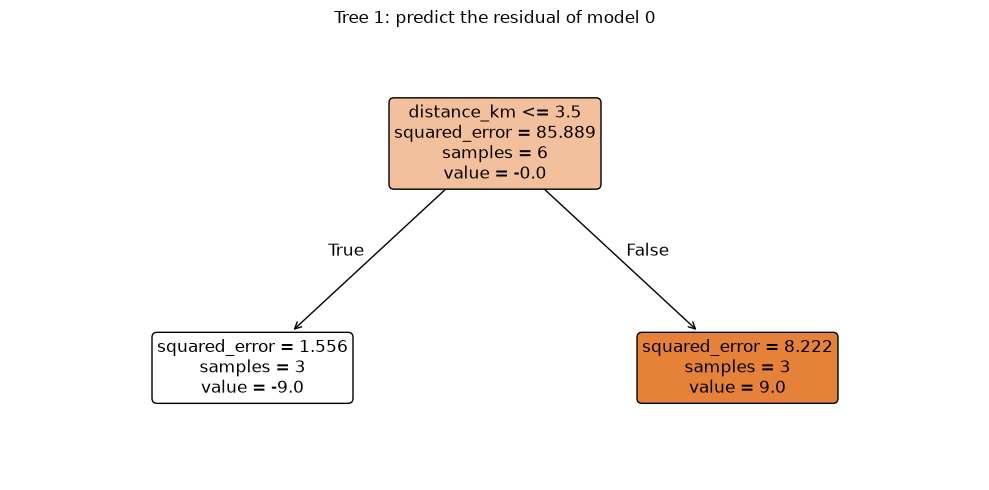

In [7]:
fig, ax = plt.subplots(figsize = (10, 5))
plot_tree(stump, feature_names = ['distance_km'],
filled = True, rounded = True, fontsize = 12, ax = ax)
ax.set_title("Tree 1: predict the residual of model 0")
plt.tight_layout()
plt.show()

In [10]:
num_rounds = 6
rate = 0.5
current = np.full_like(y_toy, y_toy.mean())
manual_trees = []
manual_history = [current.copy()]

for stage in range(1, num_rounds +1):
    residual = y_toy - current
    tree = DecisionTreeRegressor(max_depth = 1, random_state = 42)
    tree.fit(x_toy.reshape(-1, 1), residual)
    current = current + rate * tree.predict(x_toy.reshape(-1,1))
    manual_trees.append(tree)
    manual_history.append(current.copy())
    print(f"Stage {stage}: training MSE = "
            f"{mean_squared_error(y_toy, current):.4f}")

print("Final predictions: ", current.round(2))
print("Actual values: ", y_toy)

Stage 1: training MSE = 25.1389
Stage 2: training MSE = 9.9514
Stage 3: training MSE = 3.6988
Stage 4: training MSE = 1.8173
Stage 5: training MSE = 0.8483
Stage 6: training MSE = 0.4115
Final predictions:  [13.   14.53 14.53 28.03 31.9  34.02]
Actual values:  [12. 14. 15. 28. 32. 35.]


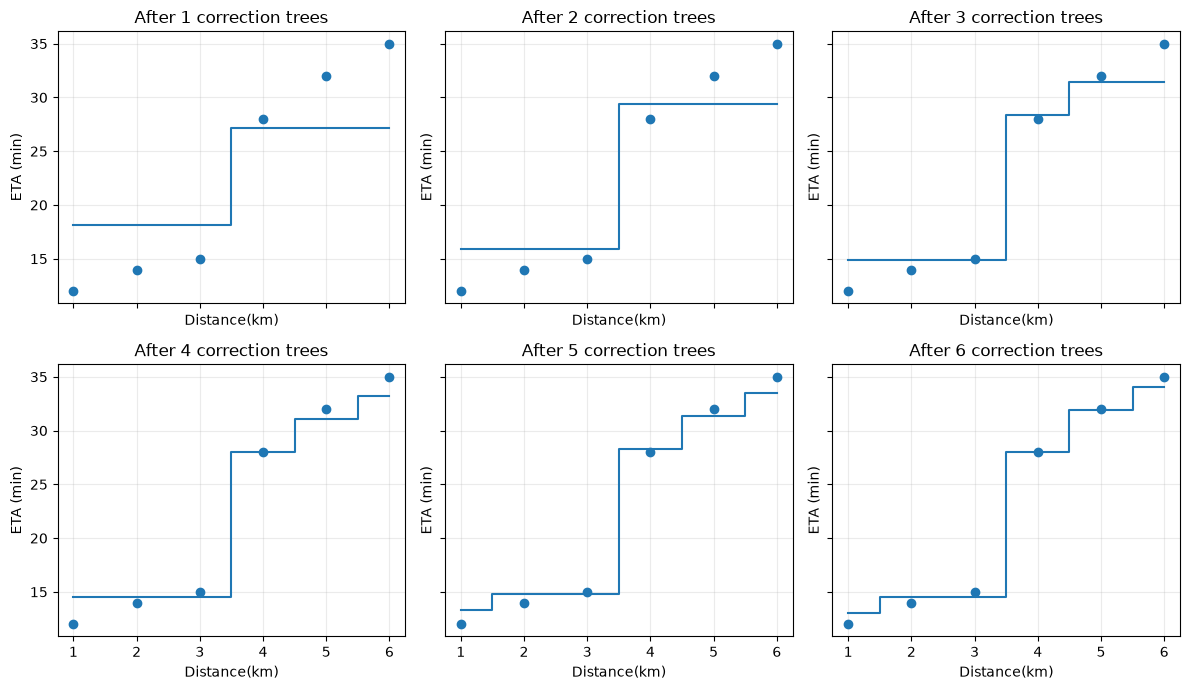

In [11]:
fig, axes = plt.subplots(2, 3, figsize = (12,7), sharex = True, sharey = True)
for stage, ax in enumerate(axes.flat, start = 1):
    ax.scatter(x_toy, y_toy, label = 'Actual', zorder = 3)
    ax.step(x_toy, manual_history[stage], where = 'mid',
    label = 'Ensemble prediction')
    
    ax.set_title(f"After {stage} correction trees")
    ax.set_xlabel("Distance(km)")
    ax.set_ylabel("ETA (min)")
    ax.grid(alpha = 0.25)

plt.tight_layout()
plt.show()


In [12]:
x_toy

array([1., 2., 3., 4., 5., 6.])

In [18]:
def predict_manual(x_new):
    values = np.asarray(x_new, dtype = float).reshape(-1, 1)
    pred = np.full(len(values), y_toy.mean())
    for tree in manual_trees:
        pred += rate * tree.predict(values)
    return pred

print("3 km vs 5 km", predict_manual([10.]).round(2))


3 km vs 5 km [34.02]


In [19]:
gbr_toy = GradientBoostingRegressor(
    loss = 'squared_error', n_estimators = 6,
    learning_rate = 0.5, max_depth = 1, 
    criterion = 'squared_error', random_state = 42
)

gbr_toy.fit(x_toy.reshape(-1, 1), y_toy)
sklearn_pred = gbr_toy.predict(x_toy.reshape(-1,1))
print("Manual: ", manual_history[-1].round(3))
print("Sk learn model: ", sklearn_pred.round(3))
print("Max absolute difference: ",
round(np.max(np.abs(manual_history[-1] - sklearn_pred)), 8))

Manual:  [13.001 14.526 14.526 28.026 31.898 34.023]
Sk learn model:  [13.001 14.526 14.526 28.026 31.898 34.023]
Max absolute difference:  0.0


In [ ]:
rng = np.random.default_rng(SEED)
n = 1200
distance = rng.uniform(1, 15, n)
traffic = rng.uniform(0, 1, n)
rain = rng.binomial(1, 0.28, n)
peak = rng.binomial(1, 0.42, n)
noise = rng.normal(0, 2.8, n)

actual_eta = (7 + 2.4*distance + 9*traffic + 6*rain +
              5*peak + 1.05*distance*traffic +
              4*rain*traffic + 3.5*np.sin(distance/2.0) + noise)

df = pd.DataFrame({
    'distance_km': distance, 'traffic_score': traffic,
    'rain': rain, 'peak_hour': peak,
    'actual_eta_min': actual_eta
})
print(df.head(5).round(2).to_string(index=False))
print('Dataset shape:', df.shape)